<a href="https://colab.research.google.com/github/Ahowardjr/MSSP6070/blob/main/WeeklyModules/Week%2011/Week_11_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import geopandas as gpd

import pandas as pd

boundaries = gpd.read_file("/content/california-congressional-districts (1).geojson")
population = pd.read_csv("/content/CA_Legislative_Districts (1).csv")

In [12]:
# Keep the columns needed for the population maps
population = population.rename(columns={
    "DISTRICT": "district",
    "POPULATION": "population",
    "AREA": "area_sq_mi",
    "IDEAL_VALU": "ideal_population"
})

population = population[
    ["district", "population", "area_sq_mi", "ideal_population"]
].set_index("district").sort_index()

# Organize the supplied boundaries by district number
supplied = {
    int(feature["properties"]["Name"]): feature["geometry"]
    for feature in geojson["features"]
}

print(f"Population records: {len(population)}")
print(f"District boundaries: {len(supplied)}")
display(population.head())

Population records: 52
District boundaries: 53


,population,area_sq_mi,ideal_population
district,,,
1,760066,27014.63,760066
2,760067,14613.65,760066
3,760065,22035.87,760066
4,760065,3923.91,760066
5,760065,9962.22,760066


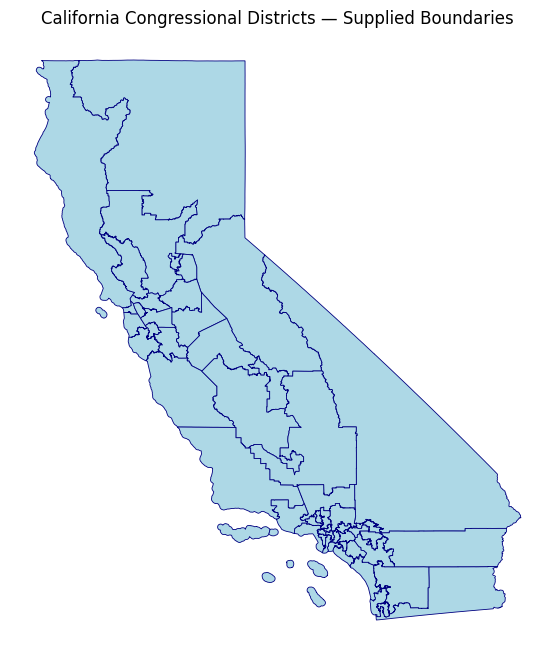

In [13]:
import geopandas as gpd
import matplotlib.pyplot as plt

boundaries = gpd.GeoDataFrame.from_features(geojson["features"], crs="EPSG:4326")

ax = boundaries.plot(
    figsize=(8, 8),
    color="lightblue",
    edgecolor="navy",
    linewidth=0.6
)
ax.set_title("California Congressional Districts — Supplied Boundaries")
ax.set_axis_off()
plt.show()

In [14]:
import requests

url = (
    "https://services3.arcgis.com/uknczv4rpevve42E/arcgis/rest/services/"
    "California_US_Congressional_Districts_Map_2020/FeatureServer/0/query"
)

response = requests.get(url, params={
    "where": "1=1",
    "outFields": "DISTRICT",
    "outSR": 4326,
    "geometryPrecision": 5,
    "f": "geojson"
}, timeout=90)
response.raise_for_status()

official = gpd.GeoDataFrame.from_features(
    response.json()["features"], crs="EPSG:4326"
)
official["district"] = official["DISTRICT"].astype(int)

districts = official[["district", "geometry"]].merge(
    population, left_on="district", right_index=True, validate="one_to_one"
)

print(f"Matched districts: {len(districts)}")

Matched districts: 52


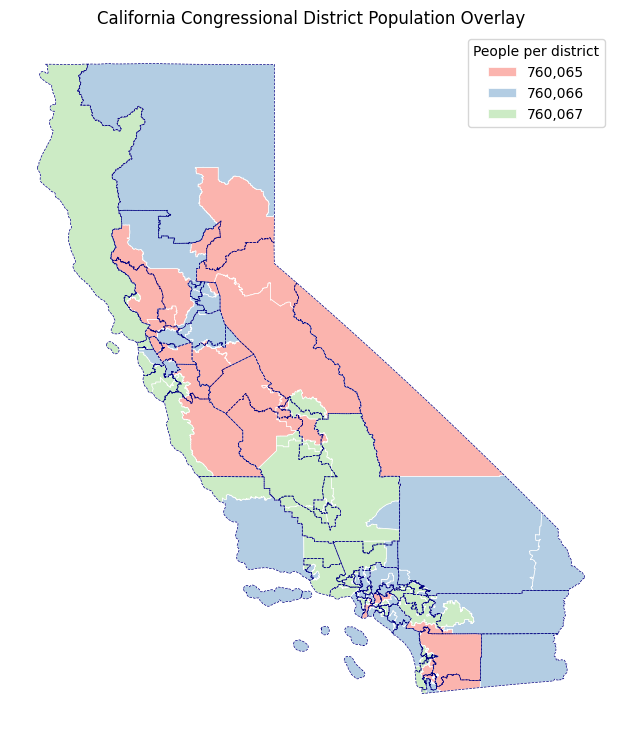

In [15]:
# Treat the three population totals as separate color categories
districts["population_label"] = districts["population"].map("{:,}".format)

ax = districts.plot(
    column="population_label",
    categorical=True,
    cmap="Pastel1",
    legend=True,
    legend_kwds={"title": "People per district", "loc": "upper right"},
    edgecolor="white",
    linewidth=0.5,
    figsize=(9, 9)
)

boundaries.boundary.plot(
    ax=ax, color="navy", linestyle="--", linewidth=0.5
)

ax.set_title("California Congressional District Population Overlay")
ax.set_axis_off()
plt.show()

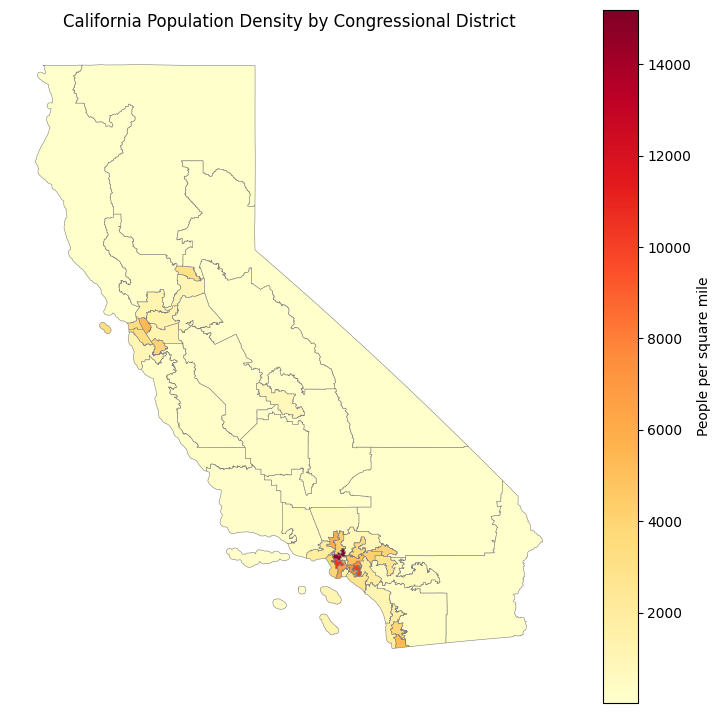

In [16]:
districts["density"] = districts["population"] / districts["area_sq_mi"]

ax = districts.plot(
    column="density",
    cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": "People per square mile"},
    edgecolor="gray",
    linewidth=0.4,
    figsize=(9, 9)
)

ax.set_title("California Population Density by Congressional District")
ax.set_axis_off()
plt.show()